In [1]:
import numpy as np
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "qqp"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 363846
    })
    validation: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 40430
    })
    test: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 390965
    })
})

In [5]:
raw_datasets['train']

Dataset({
    features: ['question1', 'question2', 'label', 'idx'],
    num_rows: 363846
})

In [6]:
from datasets import DatasetDict

In [7]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [8]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 363846
    })
    validation: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 40430
    })
    test: Dataset({
        features: ['question1', 'question2', 'label', 'idx'],
        num_rows: 390965
    })
})

In [9]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'question1': 'How is the life of a math student? Could you describe your own experiences?',
 'question2': 'Which level of prepration is enough for the exam jlpt5?',
 'label': 0,
 'idx': 0}

In [10]:
raw_train_dataset[5]['question1'], raw_train_dataset[5]['question2']

("How not to feel guilty since I am Muslim and I'm conscious we won't have sex together?",
 "I don't beleive I am bulimic, but I force throw up atleast once a day after I eat something and feel guilty. Should I tell somebody, and if so who?")

In [11]:
raw_train_dataset[5]['label']

0

In [12]:
raw_train_dataset[5]['idx']

5

In [13]:
raw_train_dataset.features

{'question1': Value('string'),
 'question2': Value('string'),
 'label': ClassLabel(names=['not_duplicate', 'duplicate']),
 'idx': Value('int32')}

# 2. Preprocess

In [14]:
def tokenize_function(example):
    return tokenizer(example["question1"], example["question2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

Map: 100%|██████████| 40430/40430 [00:00<00:00, 57749.13 examples/s]


DatasetDict({
    train: Dataset({
        features: ['question1', 'question2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 363846
    })
    validation: Dataset({
        features: ['question1', 'question2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 40430
    })
    test: Dataset({
        features: ['question1', 'question2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 390965
    })
})

# 3. Preparing for Training

In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [16]:
tokenized_datasets = tokenized_datasets.remove_columns(["question1", "question2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [17]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [18]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 62]),
 'token_type_ids': torch.Size([32, 62]),
 'attention_mask': torch.Size([32, 62])}

# 4. Load Model

In [19]:
import sys
sys.path.insert(0, '../')

In [20]:
from Bert_model.modeling_bert import BertForSequenceClassification

In [21]:
# id2label, label2id dicts for the outputs for the model
labels = tokenized_datasets["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

In [22]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [24]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(0.7232, grad_fn=<NllLossBackward0>) torch.Size([32, 2])


In [25]:
outputs.keys()

odict_keys(['loss', 'logits', 'hidden_states', 'attentions'])

In [26]:
device = torch.device("cuda:1") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)

device

device(type='cuda', index=1)

### Loading Trained Weights

In [27]:
load_path = '../glue_fine_tune/weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [28]:
from train_eval_func import eval_loop

In [29]:
eval_loop(model, val_dataloader, task_name, device)[0]

{'accuracy': 0.9102151867425179, 'f1': 0.8799841301329101}

# 5. Similarity Analysis

In [30]:
from CKA import CKAEvaluator

cka_eval = CKAEvaluator(device)

In [31]:
from CKA import SentenceCKARedundancy

headsCka_eval = SentenceCKARedundancy(device)

In [32]:
def adjacent_similarity_stats(
    similarity_scores, 
    thresold = 0.80,
    disp_sim_score=True, 
    disp_group_count=True
):
    adj_similarities = []
    for i in range(1, len(similarity_scores)):
        adj_similarities.append(similarity_scores[i-1][i])

    if disp_sim_score:
        print("Similarity Scores:", adj_similarities)

    high_pair_count = 0
    for pair in adj_similarities:
        if pair > thresold:
            high_pair_count += 1
    
    if disp_group_count:
        print("Number of High Similar Pairs:", high_pair_count)

    return adj_similarities, high_pair_count

### Using Training Data on CLS Token only

In [33]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:50<00:00,  2.26it/s]

  Reps Similarity Stats:
    Average: 0.913982
    Highest: 0.989863
    Lowest:  0.726306

  Atts Similarity Stats:
    Average: 0.950661
    Highest: 0.990862
    Lowest:  0.856384
  MHA Similarity Stats:
    Average: 0.914143
    Highest: 0.983963
    Lowest:  0.786669
  Pre Wo Similarity Stats:
    Average: 0.757359
    Highest: 0.873917
    Lowest:  0.561808
  Sublayer Similarity Stats:
    Average: 0.944947
    Highest: 0.992241
    Lowest:  0.747144
  Pre Wo Sublayer Similarity Stats:
    Average: 0.817819
    Highest: 0.949388
    Lowest:  0.582105


In [34]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:37<00:00,  3.03it/s]

  Sub Out Similarity Stats:
    Average: 0.857583
    Highest: 0.989666
    Lowest:  0.525789


In [35]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

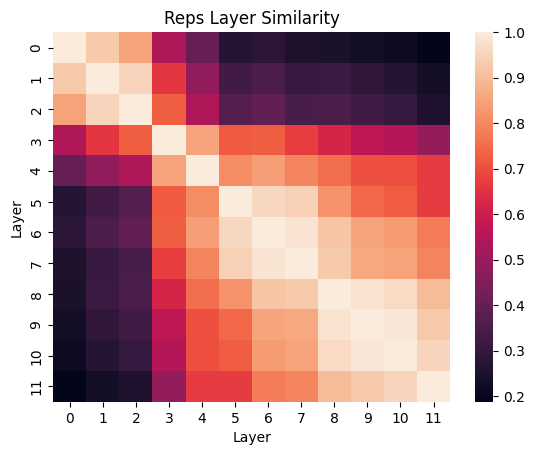

In [36]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [37]:
_,_ = adjacent_similarity_stats(reps_similarity)

Similarity Scores: [0.92998564, 0.94962424, 0.72630584, 0.85201657, 0.80884355, 0.95641375, 0.9839939, 0.92714465, 0.9780757, 0.98986274, 0.9515365]
Number of High Similar Pairs: 10


In [38]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.85)

Similarity Scores: [0.92998564, 0.94962424, 0.72630584, 0.85201657, 0.80884355, 0.95641375, 0.9839939, 0.92714465, 0.9780757, 0.98986274, 0.9515365]
Number of High Similar Pairs: 9


In [39]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.9)

Similarity Scores: [0.92998564, 0.94962424, 0.72630584, 0.85201657, 0.80884355, 0.95641375, 0.9839939, 0.92714465, 0.9780757, 0.98986274, 0.9515365]
Number of High Similar Pairs: 8


Text(50.722222222222214, 0.5, 'Layer')

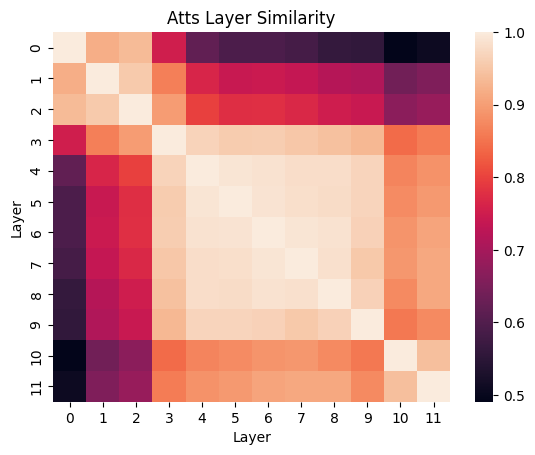

In [40]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [41]:
_,_ = adjacent_similarity_stats(atts_similarity)

Similarity Scores: [0.91885805, 0.9547035, 0.89677435, 0.96812534, 0.9903228, 0.9897337, 0.99086213, 0.98553646, 0.9648932, 0.85638356, 0.9410757]
Number of High Similar Pairs: 11


In [42]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.85)

Similarity Scores: [0.91885805, 0.9547035, 0.89677435, 0.96812534, 0.9903228, 0.9897337, 0.99086213, 0.98553646, 0.9648932, 0.85638356, 0.9410757]
Number of High Similar Pairs: 11


In [43]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.9)

Similarity Scores: [0.91885805, 0.9547035, 0.89677435, 0.96812534, 0.9903228, 0.9897337, 0.99086213, 0.98553646, 0.9648932, 0.85638356, 0.9410757]
Number of High Similar Pairs: 9


Text(50.722222222222214, 0.5, 'Layer')

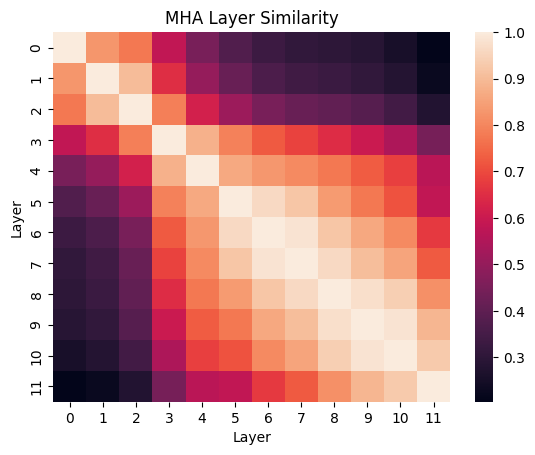

In [44]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [45]:
_,_ = adjacent_similarity_stats(mha_similarity)

Similarity Scores: [0.82858676, 0.90263826, 0.78666854, 0.8802682, 0.8660513, 0.96033734, 0.98396295, 0.9597878, 0.97454154, 0.9818167, 0.93091714]
Number of High Similar Pairs: 10


In [46]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.85)

Similarity Scores: [0.82858676, 0.90263826, 0.78666854, 0.8802682, 0.8660513, 0.96033734, 0.98396295, 0.9597878, 0.97454154, 0.9818167, 0.93091714]
Number of High Similar Pairs: 9


In [47]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.9)

Similarity Scores: [0.82858676, 0.90263826, 0.78666854, 0.8802682, 0.8660513, 0.96033734, 0.98396295, 0.9597878, 0.97454154, 0.9818167, 0.93091714]
Number of High Similar Pairs: 7


Text(50.722222222222214, 0.5, 'Layer')

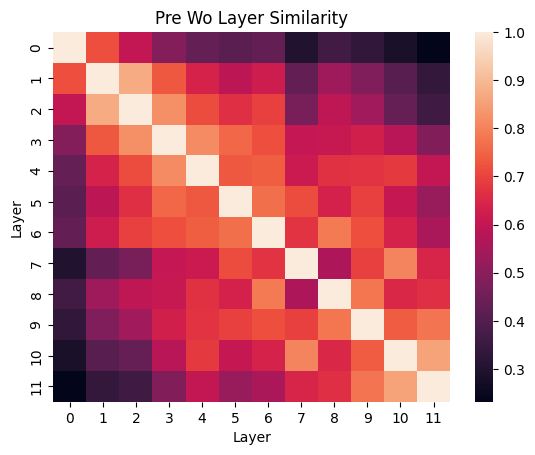

In [48]:
title = "Pre Wo Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [49]:
_,_ = adjacent_similarity_stats(pre_wo_similarity)

Similarity Scores: [0.71776086, 0.87391746, 0.8207928, 0.8140354, 0.7305211, 0.7687933, 0.67236876, 0.5618084, 0.77804154, 0.7366182, 0.85628706]
Number of High Similar Pairs: 4


In [50]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.85)

Similarity Scores: [0.71776086, 0.87391746, 0.8207928, 0.8140354, 0.7305211, 0.7687933, 0.67236876, 0.5618084, 0.77804154, 0.7366182, 0.85628706]
Number of High Similar Pairs: 2


In [51]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.9)

Similarity Scores: [0.71776086, 0.87391746, 0.8207928, 0.8140354, 0.7305211, 0.7687933, 0.67236876, 0.5618084, 0.77804154, 0.7366182, 0.85628706]
Number of High Similar Pairs: 0


Text(50.722222222222214, 0.5, 'Layer')

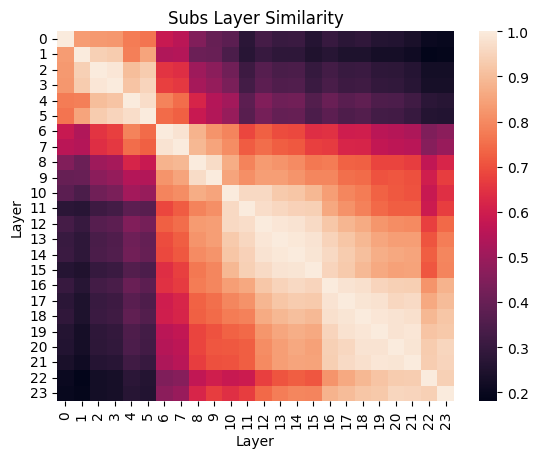

In [52]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [53]:
_,_ = adjacent_similarity_stats(sub_similarity)

Similarity Scores: [0.8346581, 0.9408891, 0.98852324, 0.9146732, 0.9686642, 0.7471443, 0.98399234, 0.889523, 0.965862, 0.85238904, 0.95882064, 0.9704199, 0.9876466, 0.992241, 0.9866719, 0.9501571, 0.9839286, 0.9847485, 0.9897076, 0.9822547, 0.9851612, 0.93553406, 0.9401678]
Number of High Similar Pairs: 22


In [54]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.85)

Similarity Scores: [0.8346581, 0.9408891, 0.98852324, 0.9146732, 0.9686642, 0.7471443, 0.98399234, 0.889523, 0.965862, 0.85238904, 0.95882064, 0.9704199, 0.9876466, 0.992241, 0.9866719, 0.9501571, 0.9839286, 0.9847485, 0.9897076, 0.9822547, 0.9851612, 0.93553406, 0.9401678]
Number of High Similar Pairs: 21


In [55]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.9)

Similarity Scores: [0.8346581, 0.9408891, 0.98852324, 0.9146732, 0.9686642, 0.7471443, 0.98399234, 0.889523, 0.965862, 0.85238904, 0.95882064, 0.9704199, 0.9876466, 0.992241, 0.9866719, 0.9501571, 0.9839286, 0.9847485, 0.9897076, 0.9822547, 0.9851612, 0.93553406, 0.9401678]
Number of High Similar Pairs: 19


Text(50.722222222222214, 0.5, 'Layer')

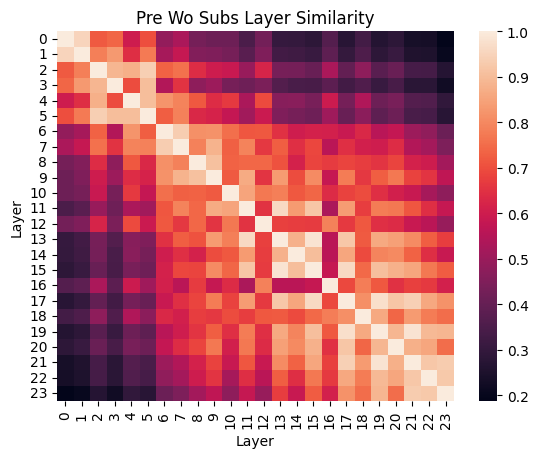

In [56]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [57]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity)

Similarity Scores: [0.94938755, 0.7812152, 0.88719743, 0.6970025, 0.9031564, 0.72685826, 0.9336473, 0.7866401, 0.9085428, 0.71773106, 0.8538179, 0.6522109, 0.67793167, 0.8776551, 0.902049, 0.58210504, 0.69078606, 0.8117914, 0.8609157, 0.8868736, 0.8751167, 0.92216194, 0.92504513]
Number of High Similar Pairs: 14


In [58]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.94938755, 0.7812152, 0.88719743, 0.6970025, 0.9031564, 0.72685826, 0.9336473, 0.7866401, 0.9085428, 0.71773106, 0.8538179, 0.6522109, 0.67793167, 0.8776551, 0.902049, 0.58210504, 0.69078606, 0.8117914, 0.8609157, 0.8868736, 0.8751167, 0.92216194, 0.92504513]
Number of High Similar Pairs: 13


In [59]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.94938755, 0.7812152, 0.88719743, 0.6970025, 0.9031564, 0.72685826, 0.9336473, 0.7866401, 0.9085428, 0.71773106, 0.8538179, 0.6522109, 0.67793167, 0.8776551, 0.902049, 0.58210504, 0.69078606, 0.8117914, 0.8609157, 0.8868736, 0.8751167, 0.92216194, 0.92504513]
Number of High Similar Pairs: 7


Text(50.722222222222214, 0.5, 'Layer')

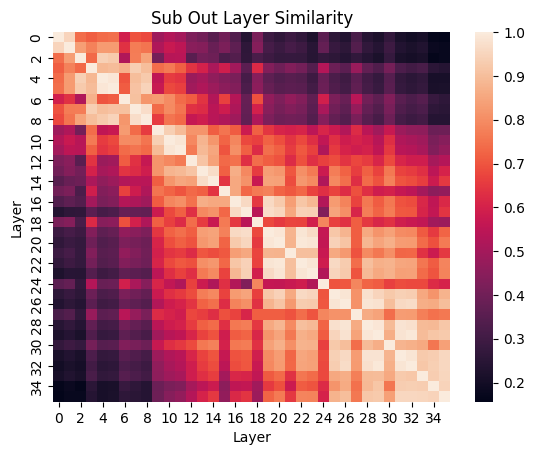

In [60]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [61]:
_,_ = adjacent_similarity_stats(sub_out_similarity)

Similarity Scores: [0.9487387, 0.8330153, 0.7347353, 0.8853115, 0.98774874, 0.7129861, 0.90566844, 0.9680532, 0.6550443, 0.9345814, 0.9836795, 0.7659206, 0.9117128, 0.96627784, 0.6413768, 0.8535487, 0.9572135, 0.5419867, 0.67765456, 0.9879941, 0.8777006, 0.90396214, 0.9865428, 0.52578896, 0.6982845, 0.98370284, 0.81109834, 0.85836434, 0.9896658, 0.8649106, 0.87993425, 0.9857066, 0.9185951, 0.9323218, 0.94558287]
Number of High Similar Pairs: 26


In [62]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.94938755, 0.7812152, 0.88719743, 0.6970025, 0.9031564, 0.72685826, 0.9336473, 0.7866401, 0.9085428, 0.71773106, 0.8538179, 0.6522109, 0.67793167, 0.8776551, 0.902049, 0.58210504, 0.69078606, 0.8117914, 0.8609157, 0.8868736, 0.8751167, 0.92216194, 0.92504513]
Number of High Similar Pairs: 13


In [63]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.94938755, 0.7812152, 0.88719743, 0.6970025, 0.9031564, 0.72685826, 0.9336473, 0.7866401, 0.9085428, 0.71773106, 0.8538179, 0.6522109, 0.67793167, 0.8776551, 0.902049, 0.58210504, 0.69078606, 0.8117914, 0.8609157, 0.8868736, 0.8751167, 0.92216194, 0.92504513]
Number of High Similar Pairs: 7


### Using Val Data on CLS Token only

In [64]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_pre_wo_similarity, val_sub_similarity, val_pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_pre_wo_stats = cka_eval.similarity_stats(val_pre_wo_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)
val_pre_wo_subs_stats = cka_eval.similarity_stats(val_pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {val_pre_wo_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {val_pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:50<00:00,  2.26it/s]

  Reps Similarity Stats:
    Average: 0.913860
    Highest: 0.989083
    Lowest:  0.727557

  Atts Similarity Stats:
    Average: 0.949866
    Highest: 0.990889
    Lowest:  0.848799
  MHA Similarity Stats:
    Average: 0.913629
    Highest: 0.983694
    Lowest:  0.787536
  Pre Wo Similarity Stats:
    Average: 0.758481
    Highest: 0.873541
    Lowest:  0.572051
  Sublayer Similarity Stats:
    Average: 0.944072
    Highest: 0.992214
    Lowest:  0.748081
  Pre Wo Sublayer Similarity Stats:
    Average: 0.817192
    Highest: 0.949960
    Lowest:  0.578174


In [65]:
val_sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

val_sub_out_stats = cka_eval.similarity_stats(val_sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {val_sub_out_stats['average']:.6f}")
print(f"    Highest: {val_sub_out_stats['max']:.6f}")
print(f"    Lowest:  {val_sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:37<00:00,  3.03it/s]

  Sub Out Similarity Stats:
    Average: 0.855332
    Highest: 0.989053
    Lowest:  0.515442


Text(50.722222222222214, 0.5, 'Layer')

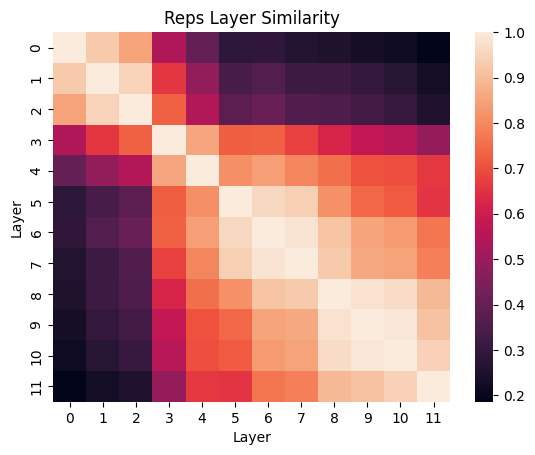

In [66]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [67]:
_,_ = adjacent_similarity_stats(val_reps_similarity)

Similarity Scores: [0.9292415, 0.9490015, 0.72755706, 0.8562058, 0.8112092, 0.957012, 0.98388386, 0.926981, 0.97871983, 0.98908293, 0.94356465]
Number of High Similar Pairs: 10


In [68]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.85)

Similarity Scores: [0.9292415, 0.9490015, 0.72755706, 0.8562058, 0.8112092, 0.957012, 0.98388386, 0.926981, 0.97871983, 0.98908293, 0.94356465]
Number of High Similar Pairs: 9


In [69]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.9)

Similarity Scores: [0.9292415, 0.9490015, 0.72755706, 0.8562058, 0.8112092, 0.957012, 0.98388386, 0.926981, 0.97871983, 0.98908293, 0.94356465]
Number of High Similar Pairs: 8


Text(50.722222222222214, 0.5, 'Layer')

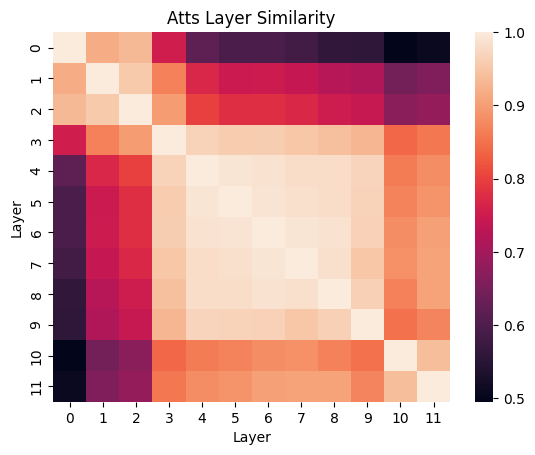

In [70]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [71]:
_,_ = adjacent_similarity_stats(val_atts_similarity)

Similarity Scores: [0.9174631, 0.95505244, 0.8984377, 0.96778536, 0.9905414, 0.98981047, 0.9908888, 0.98575, 0.96448, 0.84879935, 0.939516]
Number of High Similar Pairs: 11


In [72]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.85)

Similarity Scores: [0.9174631, 0.95505244, 0.8984377, 0.96778536, 0.9905414, 0.98981047, 0.9908888, 0.98575, 0.96448, 0.84879935, 0.939516]
Number of High Similar Pairs: 10


In [73]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.9)

Similarity Scores: [0.9174631, 0.95505244, 0.8984377, 0.96778536, 0.9905414, 0.98981047, 0.9908888, 0.98575, 0.96448, 0.84879935, 0.939516]
Number of High Similar Pairs: 9


Text(50.722222222222214, 0.5, 'Layer')

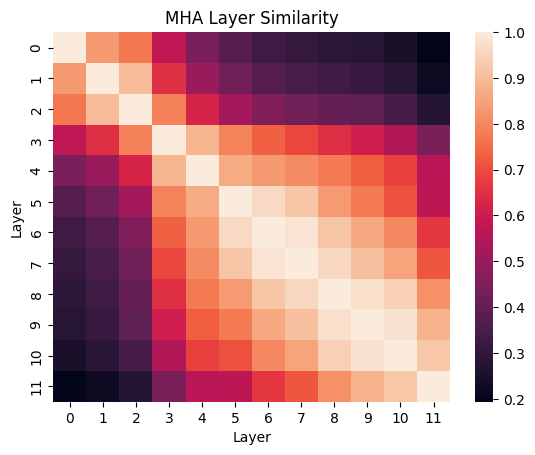

In [74]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [75]:
_,_ = adjacent_similarity_stats(val_mha_similarity)

Similarity Scores: [0.8317364, 0.9005494, 0.7875356, 0.88362366, 0.8654761, 0.9602626, 0.98369354, 0.9588703, 0.9752313, 0.9805213, 0.9224202]
Number of High Similar Pairs: 10


In [76]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.85)

Similarity Scores: [0.8317364, 0.9005494, 0.7875356, 0.88362366, 0.8654761, 0.9602626, 0.98369354, 0.9588703, 0.9752313, 0.9805213, 0.9224202]
Number of High Similar Pairs: 9


In [77]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.9)

Similarity Scores: [0.8317364, 0.9005494, 0.7875356, 0.88362366, 0.8654761, 0.9602626, 0.98369354, 0.9588703, 0.9752313, 0.9805213, 0.9224202]
Number of High Similar Pairs: 7


Text(50.722222222222214, 0.5, 'Layer')

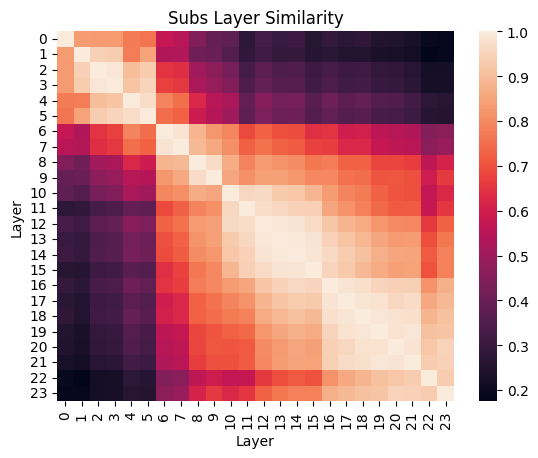

In [78]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [79]:
_,_ = adjacent_similarity_stats(val_sub_similarity)

Similarity Scores: [0.83482194, 0.9408339, 0.9885831, 0.91327786, 0.96891135, 0.74808145, 0.98375726, 0.8920052, 0.96582264, 0.8548265, 0.9576652, 0.9698324, 0.9877891, 0.9922141, 0.9860449, 0.9489748, 0.9832546, 0.98434705, 0.9890535, 0.9796555, 0.98237246, 0.92994636, 0.93159235]
Number of High Similar Pairs: 22


In [80]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.85)

Similarity Scores: [0.83482194, 0.9408339, 0.9885831, 0.91327786, 0.96891135, 0.74808145, 0.98375726, 0.8920052, 0.96582264, 0.8548265, 0.9576652, 0.9698324, 0.9877891, 0.9922141, 0.9860449, 0.9489748, 0.9832546, 0.98434705, 0.9890535, 0.9796555, 0.98237246, 0.92994636, 0.93159235]
Number of High Similar Pairs: 21


In [81]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.9)

Similarity Scores: [0.83482194, 0.9408339, 0.9885831, 0.91327786, 0.96891135, 0.74808145, 0.98375726, 0.8920052, 0.96582264, 0.8548265, 0.9576652, 0.9698324, 0.9877891, 0.9922141, 0.9860449, 0.9489748, 0.9832546, 0.98434705, 0.9890535, 0.9796555, 0.98237246, 0.92994636, 0.93159235]
Number of High Similar Pairs: 19


Text(50.722222222222214, 0.5, 'Layer')

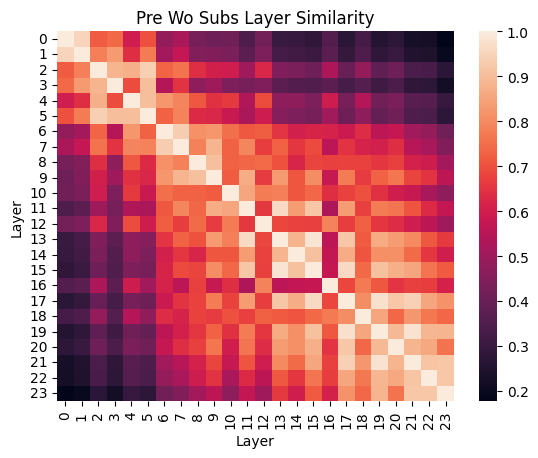

In [82]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [83]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity)

Similarity Scores: [0.9499604, 0.7794139, 0.88336986, 0.69236916, 0.90144485, 0.72804916, 0.9336012, 0.7827628, 0.90450114, 0.7202948, 0.8545138, 0.6573652, 0.6820893, 0.88358283, 0.909369, 0.5781744, 0.68494487, 0.80455667, 0.85409254, 0.8914967, 0.8826475, 0.9156711, 0.92114204]
Number of High Similar Pairs: 14


In [84]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.9499604, 0.7794139, 0.88336986, 0.69236916, 0.90144485, 0.72804916, 0.9336012, 0.7827628, 0.90450114, 0.7202948, 0.8545138, 0.6573652, 0.6820893, 0.88358283, 0.909369, 0.5781744, 0.68494487, 0.80455667, 0.85409254, 0.8914967, 0.8826475, 0.9156711, 0.92114204]
Number of High Similar Pairs: 13


In [85]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.9499604, 0.7794139, 0.88336986, 0.69236916, 0.90144485, 0.72804916, 0.9336012, 0.7827628, 0.90450114, 0.7202948, 0.8545138, 0.6573652, 0.6820893, 0.88358283, 0.909369, 0.5781744, 0.68494487, 0.80455667, 0.85409254, 0.8914967, 0.8826475, 0.9156711, 0.92114204]
Number of High Similar Pairs: 7


Text(50.722222222222214, 0.5, 'Layer')

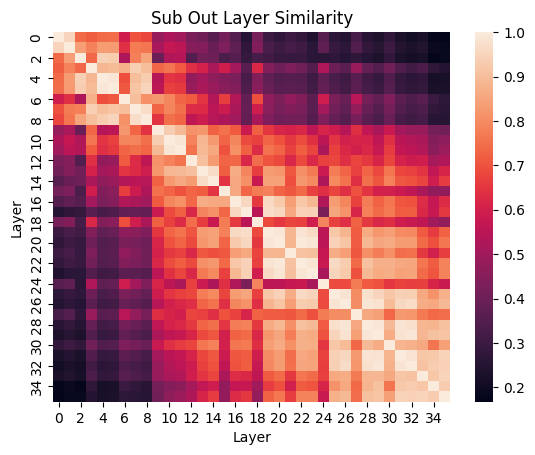

In [86]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [87]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity)

Similarity Scores: [0.9499604, 0.83482194, 0.7363256, 0.88336986, 0.9885831, 0.70793396, 0.90144485, 0.96891135, 0.64416456, 0.9336012, 0.98375726, 0.7541303, 0.90450114, 0.96582264, 0.646673, 0.8545138, 0.9576652, 0.5497264, 0.6820893, 0.9877891, 0.88262254, 0.909369, 0.9860449, 0.5154417, 0.68494487, 0.9832546, 0.8039507, 0.85409254, 0.9890535, 0.86456203, 0.8826475, 0.98237246, 0.9097317, 0.92114204, 0.93159235]
Number of High Similar Pairs: 26


In [88]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.85)

Similarity Scores: [0.9499604, 0.83482194, 0.7363256, 0.88336986, 0.9885831, 0.70793396, 0.90144485, 0.96891135, 0.64416456, 0.9336012, 0.98375726, 0.7541303, 0.90450114, 0.96582264, 0.646673, 0.8545138, 0.9576652, 0.5497264, 0.6820893, 0.9877891, 0.88262254, 0.909369, 0.9860449, 0.5154417, 0.68494487, 0.9832546, 0.8039507, 0.85409254, 0.9890535, 0.86456203, 0.8826475, 0.98237246, 0.9097317, 0.92114204, 0.93159235]
Number of High Similar Pairs: 24


In [89]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.9)

Similarity Scores: [0.9499604, 0.83482194, 0.7363256, 0.88336986, 0.9885831, 0.70793396, 0.90144485, 0.96891135, 0.64416456, 0.9336012, 0.98375726, 0.7541303, 0.90450114, 0.96582264, 0.646673, 0.8545138, 0.9576652, 0.5497264, 0.6820893, 0.9877891, 0.88262254, 0.909369, 0.9860449, 0.5154417, 0.68494487, 0.9832546, 0.8039507, 0.85409254, 0.9890535, 0.86456203, 0.8826475, 0.98237246, 0.9097317, 0.92114204, 0.93159235]
Number of High Similar Pairs: 18


### Using Training Data using Whole Sequence

In [90]:
reps_similarity, atts_similarity, mha_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [01:03<00:00,  1.81it/s]


ValueError: too many values to unpack (expected 4)

In [ ]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Val Data using Whole Sequence

In [ ]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

In [ ]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Training Data for Heads Redundancy

In [ ]:
headsCka_eval

In [ ]:
outputs.attentions['attention_head'][0].shape

In [ ]:
outputs.attentions['attention_head'][11].shape

In [ ]:
from CKA import CudaCKA

In [ ]:
from tqdm import tqdm

In [ ]:
class TestHeadRedundancyEval:
    def __init__(self, device):
        self.cuda_cka = CudaCKA(device)
 
    def collect_selected_layer_head_matrices(self, atts, layer_indices):
        """
        atts: list of length L, each (batch, heads, seq_q, seq_k)
        layer_indices: which layers to include (e.g. [3], [0,1,2], or
                       None for all layers)
 
        Returns:
            matrices: list of (batch, seq_q, seq_k) tensors, UNFLATTENED.
                      Sentence-level CKA needs the (n, n) shape intact --
                      do not flatten these.
            labels: list of (layer_idx, head_idx) tuples, same order/length
                    as matrices. Required to interpret rows/cols of the
                    returned similarity matrix once more than one layer
                    is involved.
        """
        if layer_indices is None:
            layer_indices = [i for i in range(len(atts))]  # fixed: missing ')'
 
        matrices = []
        labels = []
        for layer_idx in layer_indices:
            layer_att = atts[layer_idx]  # (batch, heads, seq_q, seq_k)
            heads = layer_att.shape[1]
            for h in range(heads):
                matrices.append(layer_att[:, h, :, :])
                labels.append((layer_idx, h))
        return matrices, labels
 
    def _accumulate_batch(self, matrices, attention_mask, scores_accum):
        """
        Adds this batch's per-sentence CKA sums into scores_accum (in place)
        and returns how many valid sentences (n_valid >= 2) contributed.
 
        Diagonal entries are CKA(head_i, head_i) for each sentence, which
        is always exactly 1.0 -- so after normalizing by n_valid_sentences
        the diagonal stays exactly 1.0, guaranteed to be the max of every
        row/column. No special-casing needed for "same head = highest
        similarity"; it falls out of CKA's own definition as long as every
        (i, i) pair is computed the same way as every (i, j) pair below.
        """
        M = len(matrices)
        batch = matrices[0].shape[0]
        n_valid_sentences = 0
 
        with torch.no_grad():
            for b in range(batch):
                # Padding-side agnostic: works regardless of left/right padding.
                valid_idx = attention_mask[b].bool()
                n_valid = int(valid_idx.sum().item())
 
                # Guard against degenerate very-short sentences where
                # linear_CKA's variance terms can be ~0 -> NaN.
                if n_valid < 2:
                    continue
                n_valid_sentences += 1
 
                for i in range(M):
                    Ai = matrices[i][b][valid_idx][:, valid_idx]  # (n_valid, n_valid)
                    for j in range(i, M):
                        Bj = matrices[j][b][valid_idx][:, valid_idx]
                        val = self.cuda_cka.linear_CKA(Ai, Bj).detach()
                        scores_accum[i, j] += val
                        if i != j:
                            scores_accum[j, i] += val
                        # i == j case (diagonal): added once, correctly,
                        # via the scores_accum[i, j] += val line above.
 
        return n_valid_sentences
 
    def att_head_redundancy_estimate(self, model, dataloader, device,
                                      max_iter=float("Inf"), layer_indices=None,
                                      attention_mask_key="attention_mask"):
        """
        Runs sentence-level CKA head-redundancy estimation over an entire
        dataloader. Diagonal of the returned matrix is guaranteed to be
        1.0 (a head is always maximally similar to itself), so every
        row/column's max similarity is its own diagonal entry.
 
        Returns:
            scores: (M, M) numpy array, M = len(layer_indices or all)*heads
            labels: list of (layer_idx, head_idx), same order as rows/cols
        """
        model.set_use_module_grafting(False)
        model.set_use_scc_status(False)
 
        n_batch = len(dataloader)
        n_steps = min(n_batch, max_iter) if max_iter != float("Inf") else n_batch
        progress_bar = tqdm(range(n_steps), desc="CKA Sublayer Evaluation")
 
        model.eval()
 
        scores = None
        labels = None
        total_valid_sentences = 0
 
        for step, batch in enumerate(dataloader):
            if step == max_iter:
                break
 
            batch = {k: v.to(device) for k, v in batch.items()}
            attention_mask = batch[attention_mask_key]
 
            with torch.no_grad():
                output = model(**batch)
 
            atts = output.attentions["attention_head"]  # list of (batch, heads, seq_q, seq_k)
 
            matrices, labels = self.collect_selected_layer_head_matrices(atts, layer_indices)
 
            if scores is None:
                M = len(matrices)
                scores = torch.zeros(M, M, device=matrices[0].device)
 
            n_valid = self._accumulate_batch(matrices, attention_mask, scores)
            total_valid_sentences += n_valid
 
            progress_bar.update(1)
 
        if total_valid_sentences == 0:
            scores.fill_(float("nan"))
        else:
            scores = scores / total_valid_sentences
 
        # Sanity: diagonal should be (numerically) 1.0 -- confirms the
        # "same head = highest similarity" property holds by construction.
        return scores.cpu().numpy(), labels

In [ ]:
test = TestHeadRedundancyEval(device)

In [ ]:
scores, labels = test.att_head_redundancy_estimate(model, train_dataloader, device, layer_indices=[10, 11], max_iter=5)

In [ ]:
for batch in train_dataloader:
    batch = {k: v.to(device) for k, v in batch.items()}
    attention_mask = batch['attention_mask']
    with torch.no_grad():
        output = model(**batch)
    break
{k: v.shape for k, v in batch.items()}

In [ ]:
len(outputs.attentions['attention_head'])

In [ ]:
outputs.attentions['attention_head'][0].shape

In [ ]:
matrices, labels = test.collect_selected_layer_head_matrices(outputs.attentions['attention_head'], [0, 1])

In [ ]:
labels

In [ ]:
len(matrices)

In [ ]:
matrices[0].shape

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sn

In [ ]:
title = "Atts Heads Similarity"
plt.title(title)
sn.heatmap(data = scores)
plt.xlabel("Heads")
plt.ylabel("Heads")

# 6. Sensitivity Score Analysis

In [91]:
from structure_prune_helper import register_importance_masks

In [92]:
register_importance_masks(
    model, device, register_pre_wo_layer=True, register_mha=True, register_mlp=True, register_mha_layer=True, register_mlp_layer=True
)

  Layer 0: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 1: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 2: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 3: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 4: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 5: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 6: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 7: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 8: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 9: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 10: Register

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [93]:
from structure_prune_helper import compute_layer_importance_scores

In [94]:
pre_wo_importance, mha_importance, ffn_importance, head_importance, neuron_importance, sublayer_importance =compute_layer_importance_scores(
    model, train_dataloader, device, max_batches=115,
    compute_mha=True, compute_ffn=True, compute_heads=True,
    compute_neurons=True, compute_pre_wo=True,
    display_separate=True, display_combined=True, display_pruning_order=True,
)

Computing importance (pre-WO layer, MHA layer, FFN layer, heads, neurons): 100%|██████████| 115/115 [00:10<00:00, 10.80it/s]


Layer Importance Summary (separate):
          Layer  Pre-WO(layer)     MHA(layer)     FFN(layer)    Heads(mean)  Neurons(mean)
  ------------------------------------------------------------------------------------------
  0                     0.9666         0.9304         0.8725         0.0000         0.0000
  1                     0.7158         0.7221         0.7090         0.0000         0.0000
  2                     1.0000         1.0000         1.0000         0.0000         0.0000
  3                     0.9108         0.7747         0.9177         0.0000         0.0000
  4                     0.6832         0.7864         0.8621         0.0000         0.0000
  5                     0.7479         0.7744         0.8153         0.0000         0.0000
  6                     0.5963         0.5602         0.6375         0.0000         0.0000
  7                     0.4668         0.5211         0.6725         0.0000         0.0000
  8                     0.4563         0.4568     

In [95]:
pre_wo_importance

array([0.9665982 , 0.7157815 , 1.        , 0.9107662 , 0.6831609 ,
       0.747913  , 0.5963201 , 0.46675745, 0.45628846, 0.5003066 ,
       0.46728617, 0.40410173], dtype=float32)

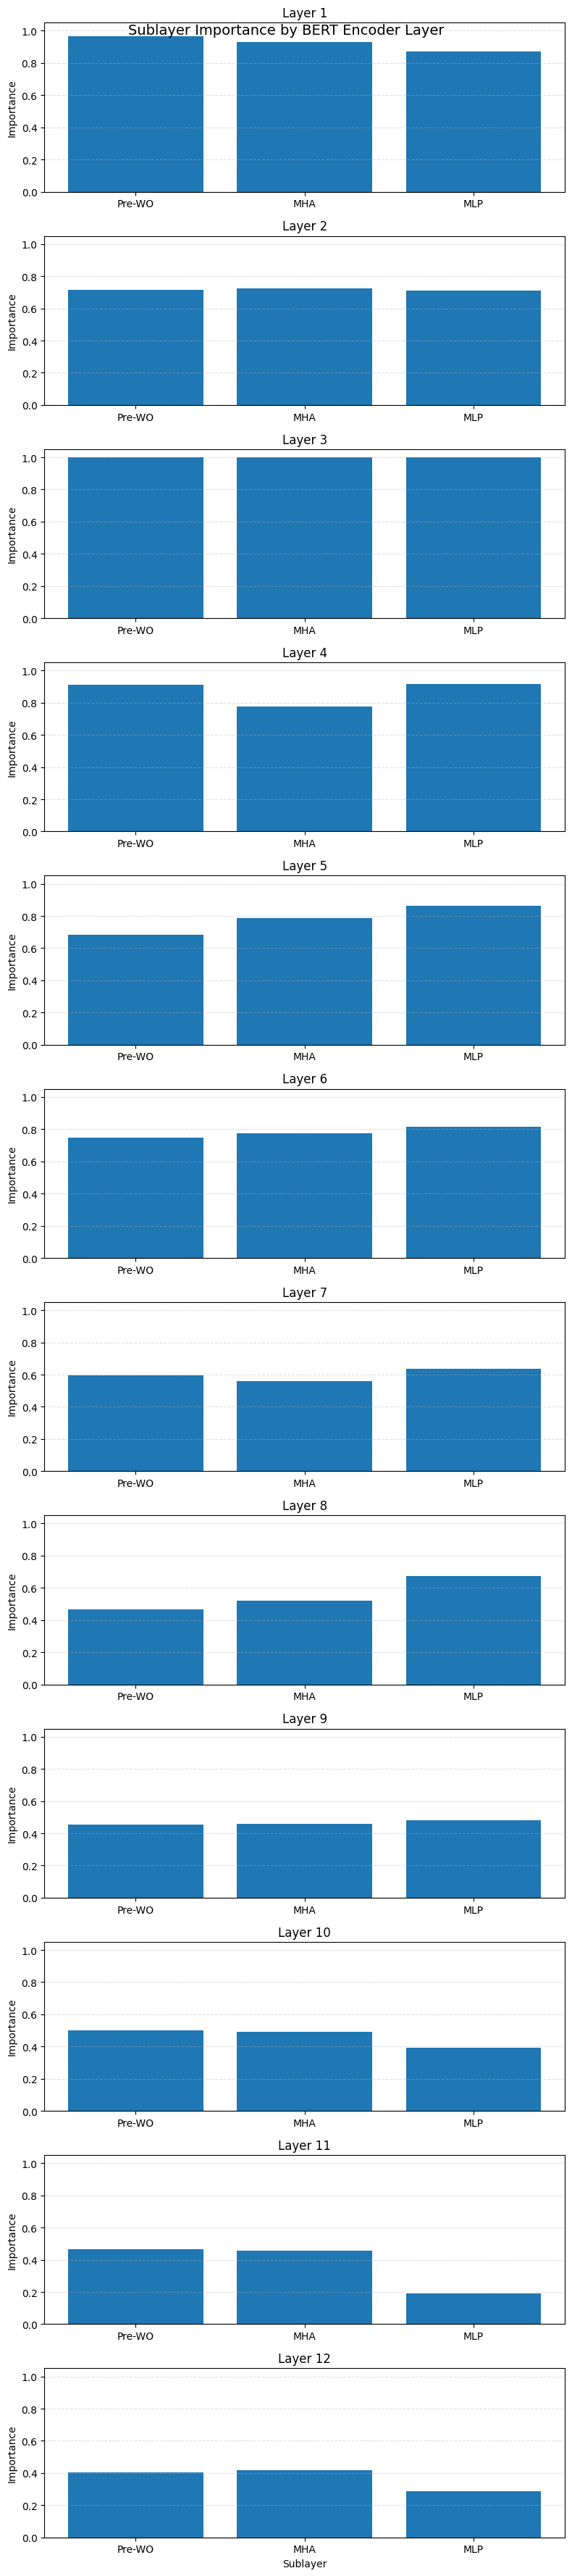

In [96]:
import matplotlib.pyplot as plt
import numpy as np

# Importance scores returned by compute_layer_importance_scores()
# pre_wo_importance, mha_importance, ffn_importance

n_layers = len(pre_wo_importance)

fig, axes = plt.subplots(
    n_layers, 1,
    figsize=(8, 3 * n_layers),
    sharey=True
)

# Handle the case of a model with only one layer
if n_layers == 1:
    axes = [axes]

labels = ["Pre-WO", "MHA", "MLP"]

for layer_idx, ax in enumerate(axes):
    scores = [
        pre_wo_importance[layer_idx],
        mha_importance[layer_idx],
        ffn_importance[layer_idx],
    ]

    ax.bar(labels, scores)
    ax.set_title(f"Layer {layer_idx + 1}")
    ax.set_ylabel("Importance")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[-1].set_xlabel("Sublayer")
fig.suptitle("Sublayer Importance by BERT Encoder Layer", fontsize=14)
plt.tight_layout()
plt.show()

### Using Training Data on CLS Token only

In [97]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:51<00:00,  2.24it/s]

  Reps Similarity Stats:
    Average: 0.912753
    Highest: 0.989872
    Lowest:  0.722538

  Atts Similarity Stats:
    Average: 0.951150
    Highest: 0.990808
    Lowest:  0.854677
  MHA Similarity Stats:
    Average: 0.912791
    Highest: 0.983374
    Lowest:  0.786525
  Pre Wo Similarity Stats:
    Average: 0.756671
    Highest: 0.872761
    Lowest:  0.571527
  Sublayer Similarity Stats:
    Average: 0.944002
    Highest: 0.992199
    Lowest:  0.745145
  Pre Wo Sublayer Similarity Stats:
    Average: 0.817962
    Highest: 0.948345
    Lowest:  0.585269


In [98]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:38<00:00,  2.97it/s]

  Sub Out Similarity Stats:
    Average: 0.856029
    Highest: 0.989699
    Lowest:  0.515374


In [99]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

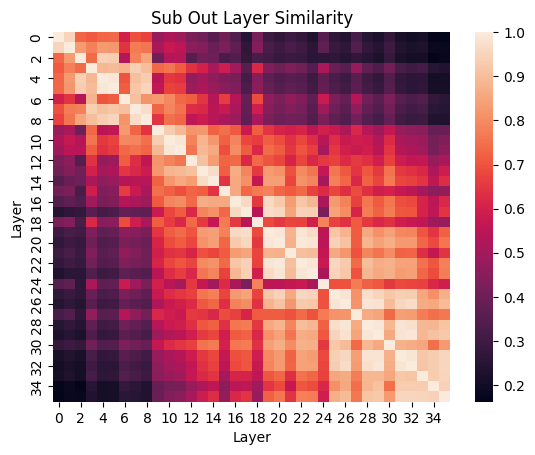

In [100]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [101]:
sub_out_similarity.shape 

(36, 36)

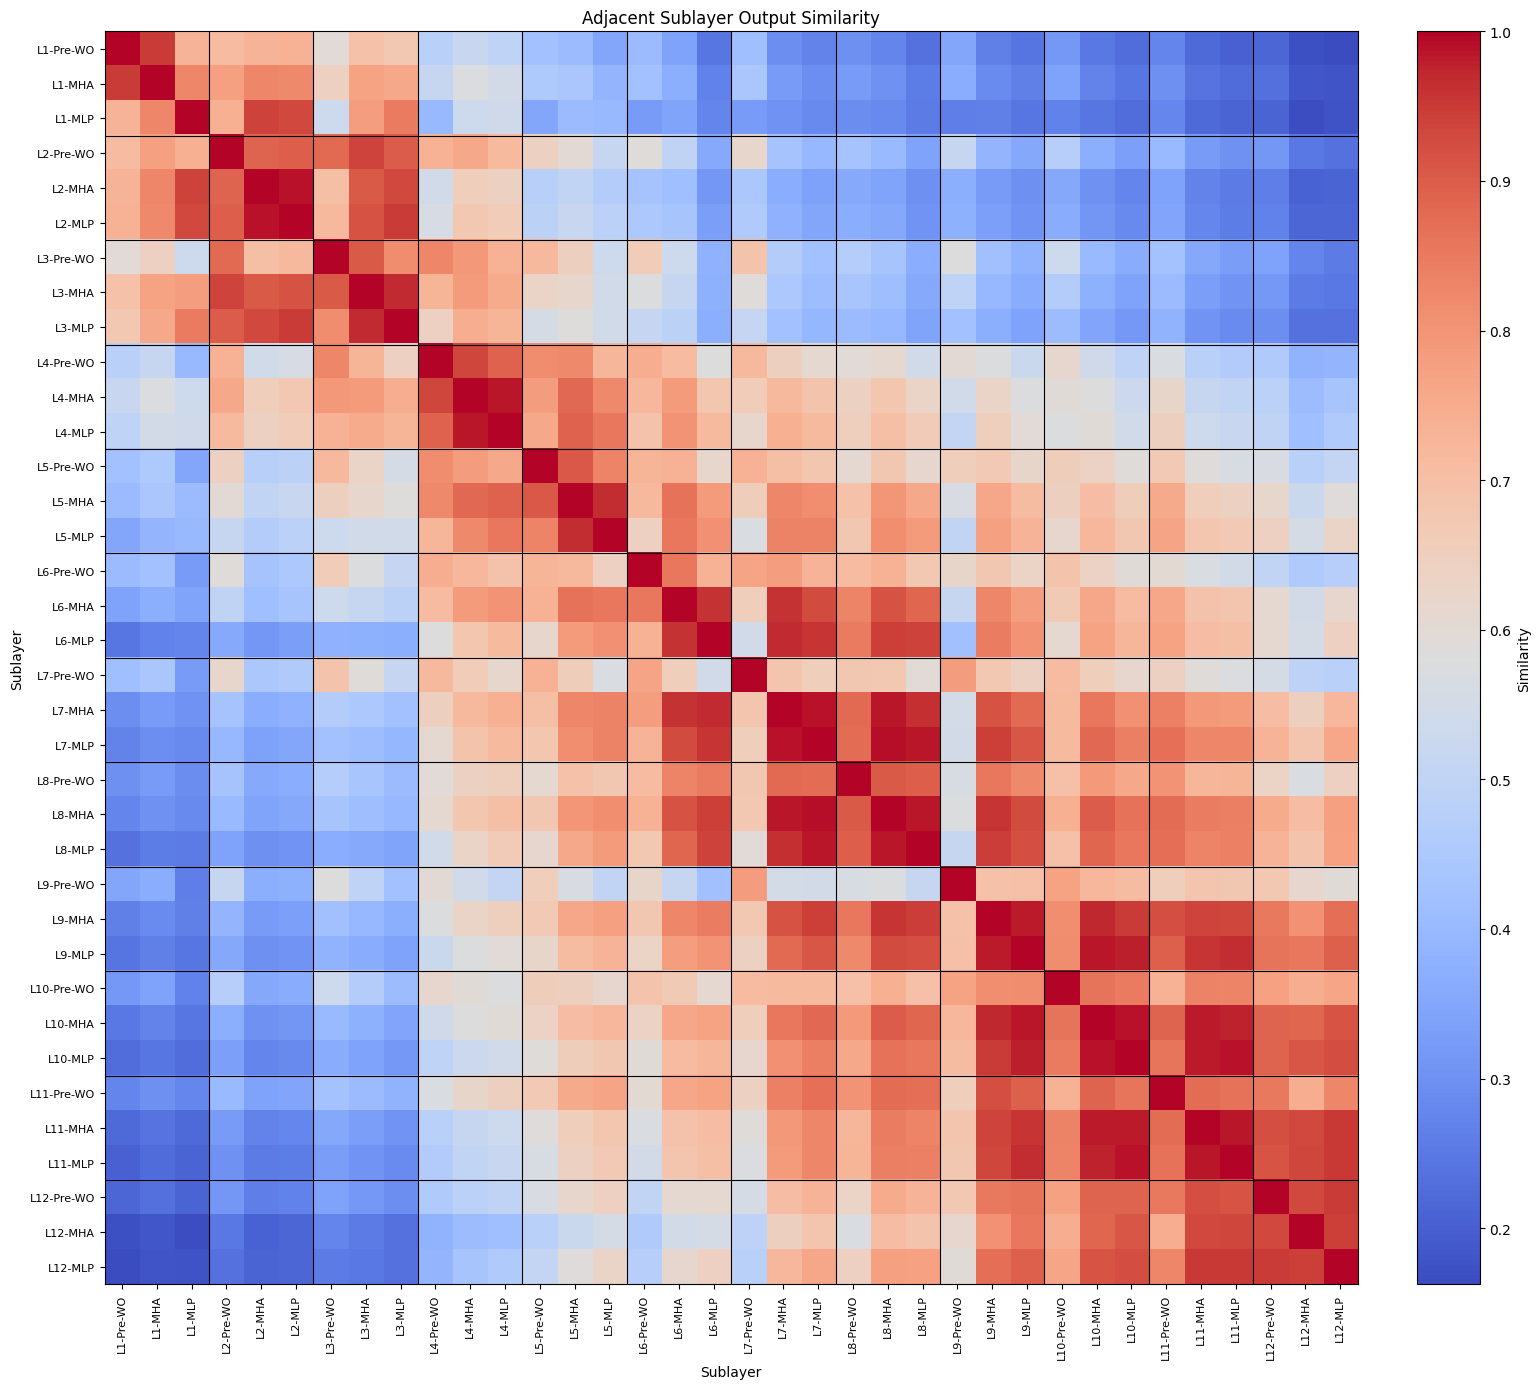

In [102]:
import matplotlib.pyplot as plt
import numpy as np

# sub_out_similarity: (36, 36)
n_layers = 12
sublayers = ["Pre-WO", "MHA", "MLP"]

labels = [
    f"L{layer + 1}-{sub}"
    for layer in range(n_layers)
    for sub in sublayers
]

fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(
    sub_out_similarity,
    cmap="coolwarm",
    interpolation="nearest",
    aspect="equal"
)

# Label every sublayer
ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels, fontsize=8)

# Add boundaries between encoder layers
for boundary in range(3, n_layers * 3, 3):
    ax.axhline(boundary - 0.5, color="black", linewidth=0.8)
    ax.axvline(boundary - 0.5, color="black", linewidth=0.8)

# Color scale
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Similarity")

ax.set_title("Adjacent Sublayer Output Similarity")
ax.set_xlabel("Sublayer")
ax.set_ylabel("Sublayer")

plt.tight_layout()
plt.show()